In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
plt.style.use("ggplot")

In [4]:

df = pd.read_csv(
    "ShortenDataSet.csv",)


In [5]:
df

,LABEL,TEXT
0,ham,Your opinion about me? 1. Over 2. Jada 3. Kusr...
1,ham,What's up? Do you want me to come online? If y...
2,ham,So u workin overtime nigpun?
3,ham,"Also sir, i sent you an email about how to log..."
4,Smishing,Please Stay At Home. To encourage the notion o...
...,...,...
5966,ham,:( but your not here....
5967,ham,Becoz its &lt;#&gt; jan whn al the post ofic...
5968,ham,Its a valentine game. . . send dis msg to all ...
5969,ham,We r outside already.


In [6]:
df.shape

(5971, 2)

In [7]:
df.dtypes

LABEL    str
TEXT     str
dtype: object

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5971 entries, 0 to 5970
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   LABEL   5971 non-null   str  
 1   TEXT    5971 non-null   str  
dtypes: str(2)
memory usage: 93.4 KB


In [9]:
df.isnull().sum().sum()

np.int64(0)

In [10]:
df.duplicated().sum() / df.shape[0] * 100

#precentage of how many are duplicated

np.float64(1.4737899849271479)

In [11]:
df.drop_duplicates(inplace=True)

In [12]:
df

,LABEL,TEXT
0,ham,Your opinion about me? 1. Over 2. Jada 3. Kusr...
1,ham,What's up? Do you want me to come online? If y...
2,ham,So u workin overtime nigpun?
3,ham,"Also sir, i sent you an email about how to log..."
4,Smishing,Please Stay At Home. To encourage the notion o...
...,...,...
5965,ham,I'm in class. Did you get my text.
5966,ham,:( but your not here....
5967,ham,Becoz its &lt;#&gt; jan whn al the post ofic...
5968,ham,Its a valentine game. . . send dis msg to all ...


In [13]:
df["LABEL"].value_counts()

LABEL
ham         4834
Smishing     551
spam         453
Spam          23
smishing      22
Name: count, dtype: int64

In [14]:
df["LABEL"].value_counts(normalize=True)*100

LABEL
ham         82.168961
Smishing     9.365970
spam         7.700153
Spam         0.390957
smishing     0.373959
Name: proportion, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

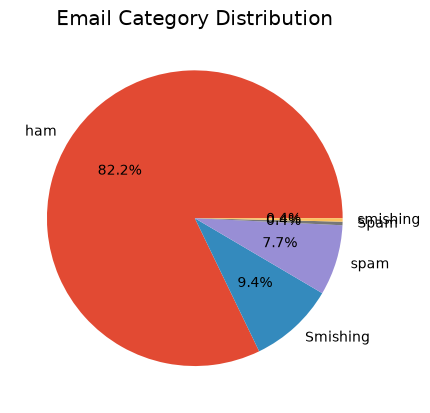

In [15]:

df["LABEL"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.ylabel("")
plt.title("Email Category Distribution")
plt.show


In [16]:
df["LABEL"] = df["LABEL"].map({
    "ham" :0,
    "Smishing" : 1,
    "smishing" : 1,
    "spam" : 2,
    "Spam" : 2
    
})

In [17]:
df.head()

,LABEL,TEXT
0,0,Your opinion about me? 1. Over 2. Jada 3. Kusr...
1,0,What's up? Do you want me to come online? If y...
2,0,So u workin overtime nigpun?
3,0,"Also sir, i sent you an email about how to log..."
4,1,Please Stay At Home. To encourage the notion o...


In [18]:
import warnings
warnings.filterwarnings("ignore")

In [19]:
import sklearn
from sklearn.model_selection import train_test_split

In [20]:
X= df["TEXT"]

In [21]:
y= df["LABEL"]

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify= y
)

In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer

tf = TfidfVectorizer(
    stop_words= "english",
    max_features= 5000,
    ngram_range= (1,2)
)

In [24]:
X_train_tf = tf.fit_transform(X_train)

In [25]:
X_test_tf = tf.transform(X_test)

In [26]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV


In [27]:
models = {
    "Navie Bayes": (
        MultinomialNB(),
        {
            "alpha" : [0.1, 0.5, 1, 2, 5]
        }
    ), 
    "LogisticRegression" : (
        LogisticRegression(
            class_weight= "balanced",
            max_iter= 1000
        ),
        {
            "C" : [0.01, 0.1, 1, 10, 100]
        }
    ),
    "Linear SWM": (
        LinearSVC(
            class_weight="balanced"
        ),
        {
            "C" : [0.01, 0.1, 1, 10, 10]
        }
        
    ), 
    "Random Forest": (
        RandomForestClassifier(
            class_weight="balanced"
        ),
        {
            "n_estimators" : [100, 200, 300],
            "max_depth" : [10, 20, None],
            "min_samples_split" : [2, 5, 10]
        }
    ),
    "Decision Tree": (
        DecisionTreeClassifier(
            class_weight="balanced"
        ),
        {
         "max_depth" : [10, 20, None],
         "min_samples_split" : [2, 5, 10]
        }
    ),

    "Gradient Boosting" : (
        GradientBoostingClassifier(),
        {
             "n_estimators" : [100, 200],
             "learning_rate" : [0.01, 0.05, 0.1 ],
             "max_depth": [3,5]
        }
    ),
     "KNN": (
         KNeighborsClassifier(),
         {
            "n_neighbors": [3,5,7,9] 
         }
     )

}

In [28]:
result = [ ]

best_models = {}

for name, (model, params) in models.items():

    search = RandomizedSearchCV(
        estimator= model,
        param_distributions= params,
        n_iter= 10,
        cv = 5,
        scoring="f1_weighted",
        n_jobs= -1
    )

    search.fit(X_train_tf,y_train)

    best_model = search.best_estimator_

    best_models[name] = best_model

    predictions = best_model.predict(X_test_tf)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, average="weighted")
    recall = recall_score(y_test, predictions, average="weighted")
    f1 = f1_score(y_test, predictions, average="weighted")

    try:
        probabilities = best_model.predict_proba(X_test_tf)
        auc = roc_auc_score(
            y_test,
            probabilities,
            multi_class="ovr",
            average="weighted",
            labels=best_model.classes_
    )
    except (ValueError, AttributeError):
        auc = np.nan

    result.append({
        "Model" : name,
        "Accuracy" : accuracy,
        "Precision" : precision,
        "Recall" : recall,
        "F1 Score" : f1,
        "ROC AUC" : auc,
        "Best Params" : search.best_params_

    })
        
    

    


In [29]:
result_df= pd.DataFrame(result)

result_df = result_df.sort_values(
    by = ["F1 Score", "ROC AUC"],
    ascending= False
)

In [30]:
result_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Best Params
2,Linear SWM,0.962617,0.961586,0.962617,0.962032,NaN,{'C': 1}
1,LogisticRegression,0.960068,0.960027,0.960068,0.960030,0.989167,{'C': 10}
3,Random Forest,0.957519,0.955104,0.957519,0.955876,0.983112,"{'n_estimators': 300, 'min_samples_split': 2, ..."
0,Navie Bayes,0.954970,0.952739,0.954970,0.953402,0.989766,{'alpha': 0.1}
5,Gradient Boosting,0.943925,0.940517,0.943925,0.941513,0.973854,"{'n_estimators': 200, 'max_depth': 5, 'learnin..."
4,Decision Tree,0.909091,0.914826,0.909091,0.911635,0.908462,"{'min_samples_split': 2, 'max_depth': None}"
6,KNN,0.901444,0.900946,0.901444,0.881004,0.840704,{'n_neighbors': 3}


In [31]:
result_df.style.background_gradient(
    cmap= "Greens",
    subset= ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Best Params
2,Linear SWM,0.962617,0.961586,0.962617,0.962032,nan,{'C': 1}
1,LogisticRegression,0.960068,0.960027,0.960068,0.960030,0.989167,{'C': 10}
3,Random Forest,0.957519,0.955104,0.957519,0.955876,0.983112,"{'n_estimators': 300, 'min_samples_split': 2, 'max_depth': None}"
0,Navie Bayes,0.954970,0.952739,0.954970,0.953402,0.989766,{'alpha': 0.1}
5,Gradient Boosting,0.943925,0.940517,0.943925,0.941513,0.973854,"{'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1}"
4,Decision Tree,0.909091,0.914826,0.909091,0.911635,0.908462,"{'min_samples_split': 2, 'max_depth': None}"
6,KNN,0.901444,0.900946,0.901444,0.881004,0.840704,{'n_neighbors': 3}


In [32]:
result_df.reset_index(inplace=True)

In [33]:
result_df.drop(columns= "index", inplace=True)

In [34]:
result_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Best Params
0,Linear SWM,0.962617,0.961586,0.962617,0.962032,NaN,{'C': 1}
1,LogisticRegression,0.960068,0.960027,0.960068,0.960030,0.989167,{'C': 10}
2,Random Forest,0.957519,0.955104,0.957519,0.955876,0.983112,"{'n_estimators': 300, 'min_samples_split': 2, ..."
3,Navie Bayes,0.954970,0.952739,0.954970,0.953402,0.989766,{'alpha': 0.1}
4,Gradient Boosting,0.943925,0.940517,0.943925,0.941513,0.973854,"{'n_estimators': 200, 'max_depth': 5, 'learnin..."
5,Decision Tree,0.909091,0.914826,0.909091,0.911635,0.908462,"{'min_samples_split': 2, 'max_depth': None}"
6,KNN,0.901444,0.900946,0.901444,0.881004,0.840704,{'n_neighbors': 3}


In [35]:
best_model_name = result_df.iloc[0]["Model"]

In [36]:
best_model_name

'Linear SWM'

In [37]:
best_model = best_models[best_model_name]

In [38]:
best_model

,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo 

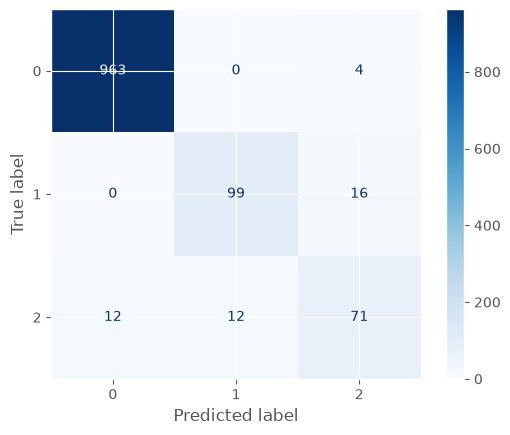

In [39]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
 best_model,
 X_test_tf,
 y_test,
 cmap = "Blues"
)

In [44]:
texts = [
    "Hey are how you!",
    "Congratulations! You won a free iPhone. Click here now.",
    "Just a reminder, we have a meeting tomorrow",
    "URGENT! Claim your $1000 Walmart gift card today!",
   "Hello from Orange. For 1 month's free access to games, news and sport, plus 10 free texts and 20 photo messages, reply YES. Terms apply: www.orange.co.uk/ow"

]

texts_vectorized = tf.transform(texts)

predictionsTwo = best_model.predict(texts_vectorized)

for i in range(len(texts)):
    prediction = predictionsTwo[i]

    label = "They are phishing or scamming! (scam)" if prediction == 2 else \
            "They are phishing or scamming! (smishing)" if prediction == 1 else \
            "This is fine! (ham)"

    print(label, ":", texts[i])


This is fine! (ham) : Hey are how you!
They are phishing or scamming! (smishing) : Congratulations! You won a free iPhone. Click here now.
This is fine! (ham) : Just a reminder, we have a meeting tomorrow
They are phishing or scamming! (smishing) : URGENT! Claim your $1000 Walmart gift card today!
They are phishing or scamming! (scam) : Hello from Orange. For 1 month's free access to games, news and sport, plus 10 free texts and 20 photo messages, reply YES. Terms apply: www.orange.co.uk/ow


In [41]:
import pickle

with open("spam_detector_model.pkl","wb" ) as file:
    pickle.dump(best_model, file)

In [42]:
with open ("tf_vectorizer2.pkl", "wb") as file:
    pickle.dump(tf, file)

print("Woohoo! It's done!")

Woohoo! It's done!
